In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("E:\Churn_Modelling.csv")

In [3]:
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [5]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [6]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [7]:
df[df.duplicated()].shape

(0, 14)

In [12]:
df['CustomerId'].value_counts().head(10)

CustomerId
15634602    1
15647311    1
15619304    1
15701354    1
15737888    1
15574012    1
15592531    1
15656148    1
15792365    1
15592389    1
Name: count, dtype: int64

In [13]:
for col in df.columns:
    if df[col].nunique()<20:
        print(df[col].value_counts())
        print('-'*50)
        

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64
--------------------------------------------------
Gender
Male      5457
Female    4543
Name: count, dtype: int64
--------------------------------------------------
Tenure
2     1048
1     1035
7     1028
8     1025
5     1012
3     1009
4      989
9      984
6      967
10     490
0      413
Name: count, dtype: int64
--------------------------------------------------
NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64
--------------------------------------------------
HasCrCard
1    7055
0    2945
Name: count, dtype: int64
--------------------------------------------------
IsActiveMember
1    5151
0    4849
Name: count, dtype: int64
--------------------------------------------------
Exited
0    7963
1    2037
Name: count, dtype: int64
--------------------------------------------------


In [14]:
# Remove RowNumber
df = df.drop('RowNumber', axis=1)

print("Shape after removing RowNumber:", df.shape)
print("Columns:", list(df.columns))

Shape after removing RowNumber: (10000, 13)
Columns: ['CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [15]:
# Remove CustomerId
df = df.drop('CustomerId', axis=1)

print("Shape after removing CustomerId:", df.shape)
print("Columns:", list(df.columns))

Shape after removing CustomerId: (10000, 12)
Columns: ['Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [16]:
# Remove Surname
df = df.drop('Surname', axis=1)

print("Shape after removing Surname:", df.shape)
print("Columns:", list(df.columns))

Shape after removing Surname: (10000, 11)
Columns: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [17]:
# Final check after removing all 3 irrelevant columns
print("=" * 50)
print("FINAL SHAPE:", df.shape)
print("=" * 50)
print("\nRemaining Columns:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")
    

FINAL SHAPE: (10000, 11)

Remaining Columns:
1. CreditScore
2. Geography
3. Gender
4. Age
5. Tenure
6. Balance
7. NumOfProducts
8. HasCrCard
9. IsActiveMember
10. EstimatedSalary
11. Exited


In [18]:
# Check unique values in Geography
print("Geography unique values:")
print(df['Geography'].value_counts())
print("\n" + "="*50)

# Check unique values in Gender
print("Gender unique values:")
print(df['Gender'].value_counts())


Geography unique values:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender unique values:
Gender
Male      5457
Female    4543
Name: count, dtype: int64


In [19]:
# One-Hot Encode Geography
df = pd.get_dummies(df, columns=['Geography'], drop_first=True)

print("Shape after encoding Geography:", df.shape)
print("\nColumns now:")
print(list(df.columns))

Shape after encoding Geography: (10000, 12)

Columns now:
['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Geography_Germany', 'Geography_Spain']


In [20]:
# Check the new columns
print(df[['Geography_Germany', 'Geography_Spain']].head(10))
print("\nValue counts:")
print("Germany:", df['Geography_Germany'].sum())
print("Spain:", df['Geography_Spain'].sum())
print("France (both = 0):", ((df['Geography_Germany'] == 0) & (df['Geography_Spain'] == 0)).sum())

   Geography_Germany  Geography_Spain
0              False            False
1              False             True
2              False            False
3              False            False
4              False             True
5              False             True
6              False            False
7               True            False
8              False            False
9              False            False

Value counts:
Germany: 2509
Spain: 2477
France (both = 0): 5014


In [21]:
from sklearn.preprocessing import LabelEncoder

# Create LabelEncoder object
le = LabelEncoder()

# Encode Gender
df['Gender'] = le.fit_transform(df['Gender'])

print("Gender encoding complete!")
print("\nGender value counts:")
print(df['Gender'].value_counts())
print("\nMapping:")
print(f"Female = {le.transform(['Female'])[0]}")
print(f"Male = {le.transform(['Male'])[0]}")

Gender encoding complete!

Gender value counts:
Gender
1    5457
0    4543
Name: count, dtype: int64

Mapping:
Female = 0
Male = 1


In [22]:
# Final check
print("=" * 50)
print("FINAL SHAPE:", df.shape)
print("=" * 50)

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 rows:")
df.head()

FINAL SHAPE: (10000, 12)

Data Types:
CreditScore            int64
Gender                 int64
Age                    int64
Tenure                 int64
Balance              float64
NumOfProducts          int64
HasCrCard              int64
IsActiveMember         int64
EstimatedSalary      float64
Exited                 int64
Geography_Germany       bool
Geography_Spain         bool
dtype: object

First 5 rows:


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,1,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,False,True


In [23]:
# Convert boolean columns to integers
df['Geography_Germany'] = df['Geography_Germany'].astype(int)
df['Geography_Spain'] = df['Geography_Spain'].astype(int)

print("After converting booleans to int:")
print(df.dtypes)

After converting booleans to int:
CreditScore            int64
Gender                 int64
Age                    int64
Tenure                 int64
Balance              float64
NumOfProducts          int64
HasCrCard              int64
IsActiveMember         int64
EstimatedSalary      float64
Exited                 int64
Geography_Germany      int64
Geography_Spain        int64
dtype: object


In [24]:
print(True == 1)    # Output: True
print(False == 0)   # Output: True
print(int(True))    # Output: 1
print(int(False))   # Output: 0

True
True
1
0


In [25]:
# Check for missing values in every column
print("Missing values per column:")
print(df.isnull().sum())

print("\n" + "="*50)
print("Total missing values:", df.isnull().sum().sum())

print("\n" + "="*50)
if df.isnull().sum().sum() == 0:
    print("✅ No missing values — dataset is clean!")
else:
    print("⚠️ Missing values found — needs handling")

Missing values per column:
CreditScore          0
Gender               0
Age                  0
Tenure               0
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
Geography_Germany    0
Geography_Spain      0
dtype: int64

Total missing values: 0

✅ No missing values — dataset is clean!


In [26]:
# List all columns with their ranges
print("Column ranges BEFORE scaling:\n")
for col in df.columns:
    if df[col].dtype in ['int64', 'float64']:
        print(f"{col:25s} Min: {df[col].min():>12.2f}  Max: {df[col].max():>12.2f}")

Column ranges BEFORE scaling:

CreditScore               Min:       350.00  Max:       850.00
Gender                    Min:         0.00  Max:         1.00
Age                       Min:        18.00  Max:        92.00
Tenure                    Min:         0.00  Max:        10.00
Balance                   Min:         0.00  Max:    250898.09
NumOfProducts             Min:         1.00  Max:         4.00
HasCrCard                 Min:         0.00  Max:         1.00
IsActiveMember            Min:         0.00  Max:         1.00
EstimatedSalary           Min:        11.58  Max:    199992.48
Exited                    Min:         0.00  Max:         1.00
Geography_Germany         Min:         0.00  Max:         1.00
Geography_Spain           Min:         0.00  Max:         1.00


In [27]:
# Separate features and target
X = df.drop('Exited', axis=1)
y = df['Exited']

print("X shape (features):", X.shape)
print("y shape (target):", y.shape)
print("\nFeature columns:", list(X.columns))
print("\nTarget column: Exited")

X shape (features): (10000, 11)
y shape (target): (10000,)

Feature columns: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain']

Target column: Exited


In [28]:
from sklearn.model_selection import train_test_split

# Split 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y    # keeps the same churn ratio in both sets
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nChurn ratio in y_train:")
print(y_train.value_counts(normalize=True).round(4))
print("\nChurn ratio in y_test:")
print(y_test.value_counts(normalize=True).round(4))

X_train shape: (8000, 11)
X_test shape: (2000, 11)
y_train shape: (8000,)
y_test shape: (2000,)

Churn ratio in y_train:
Exited
0    0.7962
1    0.2037
Name: proportion, dtype: float64

Churn ratio in y_test:
Exited
0    0.7965
1    0.2035
Name: proportion, dtype: float64


In [29]:
from sklearn.preprocessing import StandardScaler

# Columns to scale (NOT the binary ones)
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']

# Create scaler
scaler = StandardScaler()

# Fit on TRAIN only, then transform both train and test
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("✅ Scaling complete!")

✅ Scaling complete!


In [30]:
print("Column ranges AFTER scaling:\n")
for col in num_cols:
    print(f"{col:20s} Min: {X_train[col].min():>8.2f}  Max: {X_train[col].max():>8.2f}  Mean: {X_train[col].mean():>8.4f}  Std: {X_train[col].std():>6.4f}")

Column ranges AFTER scaling:

CreditScore          Min:    -3.11  Max:     2.06  Mean:  -0.0000  Std: 1.0001
Age                  Min:    -1.99  Max:     5.04  Mean:   0.0000  Std: 1.0001
Tenure               Min:    -1.73  Max:     1.72  Mean:  -0.0000  Std: 1.0001
Balance              Min:    -1.23  Max:     2.60  Mean:   0.0000  Std: 1.0001
EstimatedSalary      Min:    -1.74  Max:     1.75  Mean:  -0.0000  Std: 1.0001


In [31]:
# Show side-by-side comparison
print("=" * 65)
print(f"{'Column':<20} {'Before (min, max)':<25} {'After (min, max)':<20}")
print("=" * 65)

for col in num_cols:
    before_min = df[col].min()
    before_max = df[col].max()
    after_min = X_train[col].min()
    after_max = X_train[col].max()
    print(f"{col:<20} ({before_min:>10.1f}, {before_max:>10.1f})   ({after_min:>6.2f}, {after_max:>6.2f})")

print("=" * 65)

Column               Before (min, max)         After (min, max)    
CreditScore          (     350.0,      850.0)   ( -3.11,   2.06)
Age                  (      18.0,       92.0)   ( -1.99,   5.04)
Tenure               (       0.0,       10.0)   ( -1.73,   1.72)
Balance              (       0.0,   250898.1)   ( -1.23,   2.60)
EstimatedSalary      (      11.6,   199992.5)   ( -1.74,   1.75)


In [32]:
# These should still be 0/1
print("Binary columns (should be 0 or 1 only):\n")
for col in ['Gender', 'HasCrCard', 'IsActiveMember', 'NumOfProducts', 'Geography_Germany', 'Geography_Spain']:
    unique_vals = sorted(X_train[col].unique())
    print(f"{col:25s} Unique values: {unique_vals}")

Binary columns (should be 0 or 1 only):

Gender                    Unique values: [np.int64(0), np.int64(1)]
HasCrCard                 Unique values: [np.int64(0), np.int64(1)]
IsActiveMember            Unique values: [np.int64(0), np.int64(1)]
NumOfProducts             Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Geography_Germany         Unique values: [np.int64(0), np.int64(1)]
Geography_Spain           Unique values: [np.int64(0), np.int64(1)]


In [33]:
# Check class distribution in training data
print("Class distribution in y_train (BEFORE SMOTE):")
print(y_train.value_counts())
print("\nPercentages:")
print(y_train.value_counts(normalize=True).round(4) * 100)

print("\n" + "="*50)
print(f"Non-churners (0): {(y_train == 0).sum()}")
print(f"Churners (1):     {(y_train == 1).sum()}")
print(f"Imbalance ratio:  {(y_train == 0).sum() / (y_train == 1).sum():.2f} : 1")

Class distribution in y_train (BEFORE SMOTE):
Exited
0    6370
1    1630
Name: count, dtype: int64

Percentages:
Exited
0    79.62
1    20.37
Name: proportion, dtype: float64

Non-churners (0): 6370
Churners (1):     1630
Imbalance ratio:  3.91 : 1


In [34]:
pip install imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [35]:
from imblearn.over_sampling import SMOTE

print("✅ SMOTE imported successfully!")

✅ SMOTE imported successfully!


In [36]:
# Create SMOTE object
smote = SMOTE(random_state=42)

# Apply SMOTE ONLY on training data (NEVER on test data!)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("=" * 50)
print("SHAPES BEFORE vs AFTER SMOTE")
print("=" * 50)
print(f"X_train (before):  {X_train.shape}")
print(f"X_train (after):   {X_train_resampled.shape}")
print(f"y_train (before):  {y_train.shape}")
print(f"y_train (after):   {y_train_resampled.shape}")

SHAPES BEFORE vs AFTER SMOTE
X_train (before):  (8000, 11)
X_train (after):   (12740, 11)
y_train (before):  (8000,)
y_train (after):   (12740,)


In [37]:
print("Class distribution in y_train (AFTER SMOTE):")
print(y_train_resampled.value_counts())
print("\nPercentages:")
print(y_train_resampled.value_counts(normalize=True).round(4) * 100)

print("\n" + "="*50)
print(f"Non-churners (0): {(y_train_resampled == 0).sum()}")
print(f"Churners (1):     {(y_train_resampled == 1).sum()}")
print(f"Imbalance ratio:  {(y_train_resampled == 0).sum() / (y_train_resampled == 1).sum():.2f} : 1")

Class distribution in y_train (AFTER SMOTE):
Exited
1    6370
0    6370
Name: count, dtype: int64

Percentages:
Exited
1    50.0
0    50.0
Name: proportion, dtype: float64

Non-churners (0): 6370
Churners (1):     6370
Imbalance ratio:  1.00 : 1


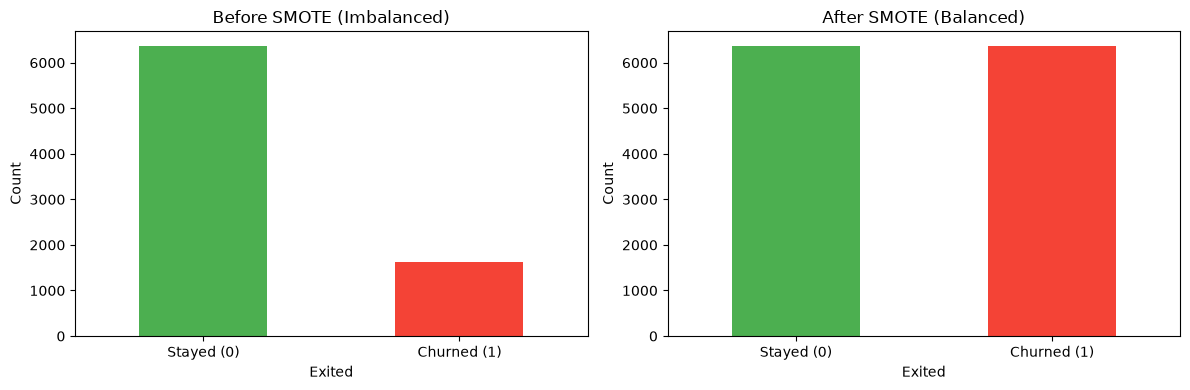

In [38]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Before SMOTE
y_train.value_counts().plot(kind='bar', ax=axes[0], color=['#4CAF50', '#F44336'])
axes[0].set_title('Before SMOTE (Imbalanced)')
axes[0].set_xlabel('Exited')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['Stayed (0)', 'Churned (1)'], rotation=0)

# After SMOTE
y_train_resampled.value_counts().plot(kind='bar', ax=axes[1], color=['#4CAF50', '#F44336'])
axes[1].set_title('After SMOTE (Balanced)')
axes[1].set_xlabel('Exited')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(['Stayed (0)', 'Churned (1)'], rotation=0)

plt.tight_layout()
plt.show()

In [39]:
# Test data should still be imbalanced
print("y_test distribution (should NOT be balanced):")
print(y_test.value_counts())
print("\nPercentages:")
print(y_test.value_counts(normalize=True).round(4) * 100)

y_test distribution (should NOT be balanced):
Exited
0    1593
1     407
Name: count, dtype: int64

Percentages:
Exited
0    79.65
1    20.35
Name: proportion, dtype: float64


In [40]:
print("=" * 55)
print("FINAL DATA SHAPES")
print("=" * 55)
print(f"X_train_resampled: {X_train_resampled.shape}")
print(f"y_train_resampled: {y_train_resampled.shape}")
print(f"X_test:            {X_test.shape}")
print(f"y_test:            {y_test.shape}")
print("=" * 55)

FINAL DATA SHAPES
X_train_resampled: (12740, 11)
y_train_resampled: (12740,)
X_test:            (2000, 11)
y_test:            (2000,)


In [41]:
print("Missing values in X_train_resampled:", X_train_resampled.isnull().sum().sum())
print("Missing values in X_test:           ", X_test.isnull().sum().sum())
print("Missing values in y_train_resampled:", y_train_resampled.isnull().sum())
print("Missing values in y_test:           ", y_test.isnull().sum())

Missing values in X_train_resampled: 0
Missing values in X_test:            0
Missing values in y_train_resampled: 0
Missing values in y_test:            0


In [42]:
print("Data types in X_train_resampled:")
print(X_train_resampled.dtypes)
print("\n" + "=" * 50)

# Check if any column is still 'object' (text)
text_cols = X_train_resampled.select_dtypes(include=['object']).columns.tolist()
if len(text_cols) == 0:
    print("✅ All columns are numeric — no text remaining!")
else:
    print(f"⚠️ Still have text columns: {text_cols}")

Data types in X_train_resampled:
CreditScore          float64
Gender                 int64
Age                  float64
Tenure               float64
Balance              float64
NumOfProducts          int64
HasCrCard              int64
IsActiveMember         int64
EstimatedSalary      float64
Geography_Germany      int64
Geography_Spain        int64
dtype: object

✅ All columns are numeric — no text remaining!


In [43]:
print("Training set (after SMOTE):")
print(y_train_resampled.value_counts())
print("\nTest set (untouched):")
print(y_test.value_counts())

print("\n" + "=" * 50)
print(f"Train balance ratio: {(y_train_resampled == 0).sum() / (y_train_resampled == 1).sum():.2f} : 1")
print(f"Test balance ratio:  {(y_test == 0).sum() / (y_test == 1).sum():.2f} : 1")

Training set (after SMOTE):
Exited
1    6370
0    6370
Name: count, dtype: int64

Test set (untouched):
Exited
0    1593
1     407
Name: count, dtype: int64

Train balance ratio: 1.00 : 1
Test balance ratio:  3.91 : 1


In [44]:
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']

print("Scaled columns — Mean & Std should be ~0 and ~1:")
print("=" * 65)
print(f"{'Column':<20} {'Mean':>10} {'Std':>10}")
print("=" * 65)
for col in num_cols:
    print(f"{col:<20} {X_train_resampled[col].mean():>10.4f} {X_train_resampled[col].std():>10.4f}")
print("=" * 65)

Scaled columns — Mean & Std should be ~0 and ~1:
Column                     Mean        Std
CreditScore             -0.0153     0.9880
Age                      0.2084     0.9838
Tenure                   0.0069     0.9931
Balance                  0.0906     0.9694
EstimatedSalary          0.0178     0.9916


In [45]:
binary_cols = ['Gender', 'HasCrCard', 'IsActiveMember', 'Geography_Germany', 'Geography_Spain']

print("Binary columns — should only have 0 or 1:")
print("=" * 60)
for col in binary_cols:
    unique_vals = sorted(X_train_resampled[col].unique())
    print(f"{col:<25} {unique_vals}")
print("=" * 60)

Binary columns — should only have 0 or 1:
Gender                    [np.int64(0), np.int64(1)]
HasCrCard                 [np.int64(0), np.int64(1)]
IsActiveMember            [np.int64(0), np.int64(1)]
Geography_Germany         [np.int64(0), np.int64(1)]
Geography_Spain           [np.int64(0), np.int64(1)]


In [46]:
# In training set
train_dupes = X_train_resampled.duplicated().sum()
print(f"Duplicate rows in X_train_resampled: {train_dupes}")

# In test set
test_dupes = X_test.duplicated().sum()
print(f"Duplicate rows in X_test:            {test_dupes}")

print("\nNote: SMOTE may create similar-looking rows (synthetic),")
print("      but exact duplicates are not a problem after scaling.")

Duplicate rows in X_train_resampled: 0
Duplicate rows in X_test:            0

Note: SMOTE may create similar-looking rows (synthetic),
      but exact duplicates are not a problem after scaling.


In [47]:
print("First 5 rows of X_train_resampled:")
print(X_train_resampled.head())

print("\n" + "=" * 50)
print("\nFirst 5 values of y_train_resampled:")
print(y_train_resampled.head())

First 5 rows of X_train_resampled:
   CreditScore  Gender       Age    Tenure   Balance  NumOfProducts  \
0     1.058568       1  1.715086  0.684723 -1.226059              1   
1     0.913626       1 -0.659935 -0.696202  0.413288              1   
2     1.079274       0 -0.184931 -1.731895  0.601687              2   
3    -0.929207       1 -0.184931 -0.005739 -1.226059              2   
4     0.427035       1  0.955079  0.339492  0.548318              2   

   HasCrCard  IsActiveMember  EstimatedSalary  Geography_Germany  \
0          1               0         1.042084                  0   
1          1               0        -0.623556                  1   
2          1               1         0.308128                  1   
3          1               0        -0.290199                  0   
4          0               1         0.135042                  1   

   Geography_Spain  
0                0  
1                0  
2                0  
3                0  
4                0  


F

In [48]:
print("=" * 65)
print("                DATA CLEANING SUMMARY")
print("=" * 65)
print(f"{'Check':<35} {'Result':<20} {'Status'}")
print("=" * 65)
print(f"{'Dropped irrelevant columns':<35} {'3 dropped':<20} {'✅'}")
print(f"{'Categorical encoding':<35} {'Completed':<20} {'✅'}")
print(f"{'Missing values':<35} {'0':<20} {'✅'}")
print(f"{'Feature scaling':<35} {'5 columns':<20} {'✅'}")
print(f"{'Class imbalance (SMOTE)':<35} {'50:50':<20} {'✅'}")
print(f"{'Train size':<35} {str(X_train_resampled.shape):<20} {'✅'}")
print(f"{'Test size':<35} {str(X_test.shape):<20} {'✅'}")
print("=" * 65)
print("           ✅ DATA IS READY FOR MODEL BUILDING!")
print("=" * 65)

                DATA CLEANING SUMMARY
Check                               Result               Status
Dropped irrelevant columns          3 dropped            ✅
Categorical encoding                Completed            ✅
Missing values                      0                    ✅
Feature scaling                     5 columns            ✅
Class imbalance (SMOTE)             50:50                ✅
Train size                          (12740, 11)          ✅
Test size                           (2000, 11)           ✅
           ✅ DATA IS READY FOR MODEL BUILDING!


In [ ]:
sz